# **OCR Benchmark: Combined Dataset (Open vs Closed Source)**

In [6]:
!pip install -q easyocr pytesseract transformers pillow pandas numpy opencv-python matplotlib seaborn Levenshtein
!pip install -q python-doctr[torch] google-cloud-vision google-generativeai openai anthropic

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import time
import io
import base64
from PIL import Image
import cv2
import Levenshtein
import warnings
warnings.filterwarnings("ignore")


[notice] A new release of pip is available: 25.0.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 25.0.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## **1. Configuration & API Keys**

In [ ]:
# Google Creds Path
os.environ['GOOGLE_APPLICATION_CREDENTIALS'] = 'Credentials_Google_Cloud.json'

# API Keys
GEMINI_API_KEY = 'YourGeminiAPIKeyHere'
GPT_API_KEY = 'YourGPTAPIKeyHere'
CLAUDE_API_KEY = 'YourClaudeAPIKeyHere'

import google.generativeai as genai
genai.configure(api_key=GEMINI_API_KEY)
gemini_model = genai.GenerativeModel('gemini-2.5-flash')

from openai import OpenAI
openai_client = OpenAI(api_key=GPT_API_KEY)

from anthropic import Anthropic
anthropic_client = Anthropic(api_key=CLAUDE_API_KEY)

from google.cloud import vision
google_client = vision.ImageAnnotatorClient()

print("✓ Closed Source Models Configured")

✓ Closed Source Models Configured


## **2. Initialisation des Modèles Open Source**

In [25]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# EasyOCR - Note: Arabic only works with English, not French
import easyocr
# Create two readers: one for English+French, one for English+Arabic
easyocr_reader_enfr = easyocr.Reader(['en', 'fr'], gpu=True if torch.cuda.is_available() else False)
easyocr_reader_enar = easyocr.Reader(['en', 'ar'], gpu=True if torch.cuda.is_available() else False)
print("✓ EasyOCR Loaded (en+fr and en+ar)")

# Tesseract
import pytesseract
pytesseract.pytesseract.tesseract_cmd = r"C:\Program Files\Tesseract-OCR\tesseract.exe"
print("✓ Tesseract Configured")

# DocTR
print("Loading DocTR...")
try:
    from doctr.io import DocumentFile
    from doctr.models import ocr_predictor
    doctr_model = ocr_predictor(pretrained=True)
    print("✓ DocTR Loaded")
except Exception as e:
    print(f"x DocTR Loading Failed: {e}")


✓ EasyOCR Loaded (en+fr and en+ar)
✓ Tesseract Configured
Loading DocTR...
✓ DocTR Loaded


## **3. Définition des Fonctions OCR**

In [26]:
def ocr_google_vision(image_path):
    try:
        with io.open(image_path, 'rb') as image_file:
            content = image_file.read()
        image = vision.Image(content=content)
        response = google_client.text_detection(image=image)
        if response.text_annotations:
            return response.text_annotations[0].description.strip()
        return ""
    except Exception as e:
        return f"Error: {e}"

def ocr_gemini(image_path):
    try:
        with open(image_path, 'rb') as f:
             image_data = f.read()
        response = gemini_model.generate_content([
            "Extract all text from this image exactly as it appears. Return only the text.",
            {"mime_type": "image/jpeg", "data": image_data}
        ])
        return response.text.strip()
    except Exception as e:
        return f"Error: {e}"

def ocr_gpt4(image_path):
    try:
        with open(image_path, "rb") as image_file:
            base64_image = base64.b64encode(image_file.read()).decode('utf-8')
        response = openai_client.chat.completions.create(
            model="gpt-4o-mini",
            messages=[
                {
                    "role": "user",
                    "content": [
                        {"type": "text", "text": "Extract all text from this image exactly as it appears."},
                        {"type": "image_url", "image_url": {"url": f"data:image/jpeg;base64,{base64_image}"}}
                    ]
                }
            ],
            max_tokens=1024
        )
        return response.choices[0].message.content.strip()
    except Exception as e:
        return f"Error: {e}"

def ocr_claude(image_path):
    try:
        with open(image_path, "rb") as image_file:
            image_data = base64.standard_b64encode(image_file.read()).decode("utf-8")
        
        message = anthropic_client.messages.create(
            model="claude-sonnet-4-20250514",
            max_tokens=1024,
            messages=[{
                "role": "user",
                "content": [
                    {"type": "image", "source": {"type": "base64", "media_type": "image/jpeg", "data": image_data}},
                    {"type": "text", "text": "Extract all text from this image exactly as it appears."}
                ]
            }]
        )
        return message.content[0].text.strip()
    except Exception as e:
        return f"Error: {e}"


def ocr_easyocr(image_path):
    try:
        # Try with English+Arabic reader first (most images contain Arabic)
        result = easyocr_reader_enar.readtext(image_path, detail=0)
        return ' '.join(result)
    except Exception as e:
        # Fallback to English+French if Arabic reader fails
        try:
            result = easyocr_reader_enfr.readtext(image_path, detail=0)
            return ' '.join(result)
        except Exception as e2:
            return f"Error: {e}"

def ocr_tesseract(image_path):
    try:
        img = Image.open(image_path)
        return pytesseract.image_to_string(img, lang='eng+fra+ara').strip()
    except Exception as e:
        return f"Error: {e}"

def ocr_doctr(image_path):
    try:
        doc = DocumentFile.from_images(image_path)
        result = doctr_model(doc)
        text_lines = []
        for page in result.pages:
            for block in page.blocks:
                for line in block.lines:
                    text_lines.append(' '.join([word.value for word in line.words]))
        return ' '.join(text_lines)
    except Exception as e:
        return f"Error: {e}"


## **4. Métriques (Accuracy, CER, WER)**

In [27]:
def calculate_ocr_metrics(predicted, ground_truth):
    predicted = str(predicted).lower().strip()
    ground_truth = str(ground_truth).lower().strip()

    if not predicted and not ground_truth:
        return {"accuracy": 100.0, "CER": 0.0, "WER": 0.0}
    if not predicted or not ground_truth:
        dist = Levenshtein.distance(predicted, ground_truth)
        max_len = max(len(predicted), len(ground_truth))
        return {"accuracy": 0.0, "CER": dist / max(max_len, 1), "WER": 1.0}

    dist_char = Levenshtein.distance(predicted, ground_truth)
    max_len = max(len(predicted), len(ground_truth))
    accuracy = (1 - dist_char / max_len) * 100
    cer = dist_char / max_len

    pred_words = predicted.split()
    gt_words = ground_truth.split()
    dist_word = Levenshtein.distance(pred_words, gt_words)
    wer = dist_word / max(len(gt_words), 1)

    return {
        "accuracy": max(0, accuracy),
        "CER": cer,
        "WER": wer
    }

## **5. Exécution du Benchmark sur Combined Dataset**

Dataset chargé: 7 images

Traitement Image: img0.jpeg


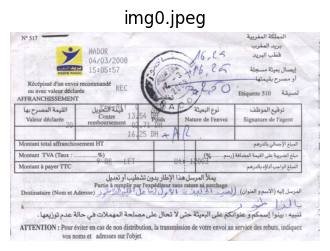

,Model,Accuracy (%),CER,WER,Time (s),Prediction (preview)
0,Google Vision,45.17,0.548,1.178,0.27,N° 517\nPOSTE MAROC\nNADOR\n04/03/2008\n15:05:...
1,Gemini,54.55,0.455,1.131,16.85,N° 517\nالمملكة المغربية\nبريد المغرب\nقطب الب...
2,GPT-4,23.85,0.761,0.972,6.73,Here is the extracted text from the image:\n\n...
3,Claude,40.17,0.598,1.346,14.66,"Looking at this postal document, I can extract..."
4,EasyOCR,37.22,0.628,1.150,5.43,"٨ 5١7 المملكة المفربية بريد المنرب ٨٩٥٥٨ 6ع,6/..."
5,Tesseract,23.10,0.769,0.963,1.67,المملكة المغربية ‎Ne‏\n\n25\n601 nib\nZZ 04/03...
6,DocTR,33.48,0.665,0.972,2.63,"N517 upidlaStedi wialdn NADOR 16,23 wwlyha 04/..."



Traitement Image: img1.jpeg


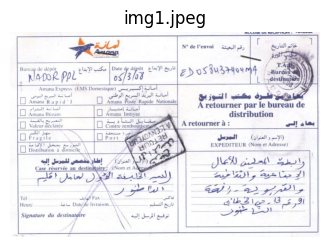

,Model,Accuracy (%),CER,WER,Time (s),Prediction (preview)
0,Google Vision,38.18,0.618,1.500,0.25,ACCUSE DE RECEPTION:\n1\nخاتم التاريخ\nمكتب ال...
1,Gemini,25.54,0.745,1.774,5.81,ACCUSE DE RECEPTION : أمانة D\nأمانة\nAmana\nB...
2,GPT-4,27.68,0.723,1.238,6.61,Here is the text extracted from the image:\n\n...
3,Claude,23.53,0.765,1.786,13.59,"Looking at this postal form, I can extract the..."
4,EasyOCR,25.21,0.748,1.333,7.87,امازة Ne dc Nen»٥i حاتم عممضم ٧٥٥٢ مكنب الإبدا...
5,Tesseract,22.41,0.776,0.905,1.16,Re) Neaeverst ‏رهم افيه‎ [UT ‏اساي‎ !\nAsane E...
6,DocTR,27.45,0.725,1.202,2.32,ACCUSE DE KECEPTIONE - NL No de l'envoi a Cll ...



Traitement Image: img2.jpeg


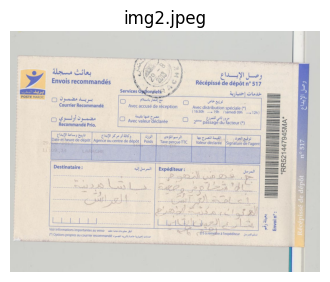

,Model,Accuracy (%),CER,WER,Time (s),Prediction (preview)
0,Google Vision,30.55,0.694,2.014,0.26,بريد المغرب\nPOSTE MAROC\nبعائث مسجلة\nEnvois ...
1,Gemini,38.47,0.615,1.824,3.07,بريد المغرب\nPOSTE MAROC\nبعائث مسجلة\nEnvois ...
2,GPT-4,20.23,0.798,1.081,6.93,Here is the extracted text from the image exac...
3,Claude,28.45,0.716,2.216,16.00,Here is all the text from the image as it appe...
4,EasyOCR,21.05,0.790,1.811,7.63,بعائث مسجلة وحسل الإيسداع Envois recommandes R...
5,Tesseract,18.28,0.817,1.622,1.96,وصل الإيداع بعائث مسجلة\n\n| Envois recommandé...
6,DocTR,20.89,0.791,1.297,1.94,Ams ile ETL Envois recommandés Récépissé de dé...



Traitement Image: img3.jpeg


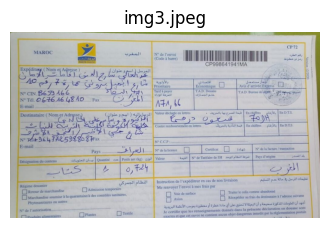

,Model,Accuracy (%),CER,WER,Time (s),Prediction (preview)
0,Google Vision,19.35,0.806,4.000,0.36,MAROC\nبريد المغرب\nالمغرب\nN° de l'envoi\n(Co...
1,Gemini,20.12,0.799,3.791,14.96,MAROC\nالمغرب\nN° de l'envoi\n(Code à barre)\n...
2,GPT-4,17.22,0.828,1.388,6.79,Here is the text extracted from the image:\n\n...
3,Claude,17.90,0.821,2.821,17.90,I can see this is a postal form from Morocco (...
4,EasyOCR,16.87,0.831,3.537,15.51,0P٦2 MAROC المغرب No ue lenvoi (٥٥٥٥ barel CP...
5,Tesseract,14.77,0.852,1.672,1.84,LL\nCP99864\n\nITU\n\nأرمستمجل\n‎‘Avis d'arriv...
6,DocTR,14.30,0.857,3.224,3.12,CP72 MAROC - I No de l'envoi a 3 - (Code à bar...



Traitement Image: img4.jpeg


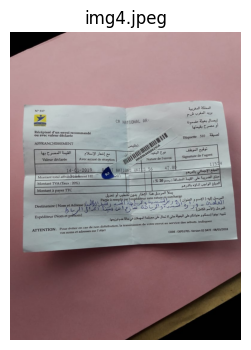

,Model,Accuracy (%),CER,WER,Time (s),Prediction (preview)
0,Google Vision,31.79,0.682,1.525,0.26,N° 517\nPORTE HARDC\nRécépissé d'un envoi reco...
1,Gemini,45.53,0.545,1.287,8.17,N° 517\nالمملكة المغربية\nبريد المغرب ش.م\nCR ...
2,GPT-4,24.05,0.760,1.010,6.51,Here is the text extracted from the image:\n\n...
3,Claude,34.16,0.658,1.554,15.84,"Looking at this postal receipt/slip, I can ext..."
4,EasyOCR,23.40,0.766,1.663,8.38,المملكة المغربية بريد CR NATIONAL AR- إيصال بس...
5,Tesseract,20.60,0.794,1.079,1.79,CR NATIONAL: AR\n\nRécépissé d'un envoi recomm...
6,DocTR,26.94,0.731,1.228,2.60,N517 lsedlSlull rotustalas CR NATIONAL AR- syo...



Traitement Image: img5.jpeg


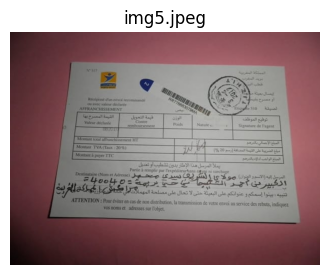

,Model,Accuracy (%),CER,WER,Time (s),Prediction (preview)
0,Google Vision,35.04,0.650,1.703,0.25,N°37\n2\nAFFRANCHISSEMENT\nRécepisse d'un envo...
1,Gemini,43.69,0.563,1.689,8.31,N° 317\nالمملكة المغربية\nبريد المغرب\nقطب الب...
2,GPT-4,10.65,0.893,1.000,1.92,I'm unable to extract text from the image. How...
3,Claude,12.33,0.877,1.297,5.35,I can see this is a postal receipt or register...
4,EasyOCR,17.81,0.822,1.000,3.67,الممرح بما و نرنن ٢٢٧ ٥٢ ٧٧٢٣ ٧ ٠7٥؟/ تمدرم...
5,Tesseract,7.61,0.924,0.986,0.46,‎a‏ بينوا إسمكم و عنوانكم على البعيثة\n\n‎nde ...
6,DocTR,18.57,0.814,1.284,1.87,van 2 1 a Recepund dun envel recommande 1 E Av...



Traitement Image: img6.jpeg


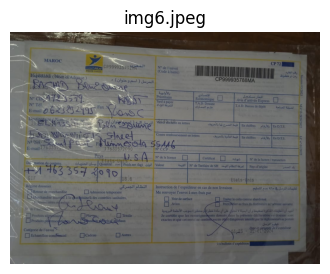

,Model,Accuracy (%),CER,WER,Time (s),Prediction (preview)
0,Google Vision,43.33,0.567,0.897,0.34,MAROC\nCP 72\nExpedier (Nom et Adresse)\nبريد ...
1,Gemini,34.24,0.658,0.983,4.53,MAROC\nبريد المغرب\nPOSTE MAROC\nCP99993579\nN...
2,GPT-4,20.62,0.794,0.905,5.92,Here's the extracted text from the image:\n\n`...
3,Claude,24.70,0.753,0.940,18.05,"Looking at this Moroccan postal form, I can ex..."
4,EasyOCR,27.02,0.730,1.052,18.01,MAROC 0٣72 CP99993573 المفدبا N% 0c 1'c0v0| (C...
5,Tesseract,23.49,0.765,0.935,2.91,"Es ==\n\nCNE WAG,\n\nec = ane enone D lee D\nN..."
6,DocTR,33.78,0.662,0.875,3.29,"MAROC CP72 - - CP999935791 N"" de lenvoi POSTE ..."


In [28]:
labels_path = 'Data/Combined_dataset/labels.csv'
images_dir = 'Data/Combined_dataset'

try:
    df = pd.read_csv(labels_path)
    print(f"Dataset chargé: {len(df)} images")
except Exception as e:
    print(f"Erreur chargement CSV: {e}")

models = [
    ("Google Vision", ocr_google_vision),
    ("Gemini", ocr_gemini),
    ("GPT-4", ocr_gpt4),
    ("Claude", ocr_claude),
    ("EasyOCR", ocr_easyocr),
    ("Tesseract", ocr_tesseract),
    ("DocTR", ocr_doctr)
]

# Stockage de tous les résultats
all_results = []

for index, row in df.iterrows():
    image_filename = row['filename']
    ground_truth = row['text']
    image_path = os.path.join(images_dir, image_filename)
    
    if not os.path.exists(image_path):
        print(f"Image introuvable: {image_filename}")
        continue

    print(f"\n{'='*50}")
    print(f"Traitement Image: {image_filename}")
    print(f"{'='*50}")
    
    try:
        pil_img = Image.open(image_path)
        plt.figure(figsize=(4, 4))
        plt.imshow(pil_img)
        plt.axis('off')
        plt.title(f"{image_filename}")
        plt.show()
    except Exception as e:
        print(f"Erreur affichage: {e}")

    img_results = []

    for model_name, model_func in models:
        start_t = time.time()
        try:
            pred_text = model_func(image_path)
            elapsed = time.time() - start_t
            
            metrics = calculate_ocr_metrics(pred_text, ground_truth)
            
            result_dict = {
                "Model": model_name,
                "Accuracy (%)": round(metrics["accuracy"], 2),
                "CER": round(metrics["CER"], 3),
                "WER": round(metrics["WER"], 3),
                "Time (s)": round(elapsed, 2),
                "Prediction (preview)": pred_text[:50] + "..." if len(pred_text) > 50 else pred_text
            }
            
            img_results.append(result_dict)
            # Stocker pour le récapitulatif final
            all_results.append({
                "Image": image_filename,
                "Model": model_name,
                "Accuracy": metrics["accuracy"],
                "CER": metrics["CER"],
                "WER": metrics["WER"],
                "Time": elapsed
            })
            
        except Exception as e:
            print(f"Erreur {model_name}: {e}")
            img_results.append({
                "Model": model_name,
                "Accuracy (%)": 0.0,
                "CER": -1,
                "WER": -1,
                "Time (s)": 0,
                "Prediction (preview)": f"Error: {e}"
            })
    
    res_df = pd.DataFrame(img_results)
    display(res_df)


## **6. Tableau Récapitulatif Final - Meilleurs Modèles**

In [29]:
# Création du DataFrame récapitulatif
results_df = pd.DataFrame(all_results)

# Calcul des moyennes par modèle
summary = results_df.groupby('Model').agg({
    'Accuracy': 'mean',
    'CER': 'mean',
    'WER': 'mean',
    'Time': 'mean'
}).reset_index()

summary.columns = ['Model', 'Avg Accuracy (%)', 'Avg CER', 'Avg WER', 'Avg Time (s)']
summary['Avg Accuracy (%)'] = summary['Avg Accuracy (%)'].round(2)
summary['Avg CER'] = summary['Avg CER'].round(3)
summary['Avg WER'] = summary['Avg WER'].round(3)
summary['Avg Time (s)'] = summary['Avg Time (s)'].round(2)

# Tri par Accuracy décroissante
summary = summary.sort_values('Avg Accuracy (%)', ascending=False).reset_index(drop=True)

print("\n" + "="*80)
print("TABLEAU RÉCAPITULATIF - PERFORMANCE GLOBALE SUR COMBINED DATASET")
print("="*80 + "\n")

display(summary)

# Identification des meilleurs modèles
print("\n" + "="*80)
print("MEILLEURS MODÈLES PAR CRITÈRE")
print("="*80)

best_accuracy = summary.loc[summary['Avg Accuracy (%)'].idxmax()]
best_cer = summary.loc[summary['Avg CER'].idxmin()]
best_wer = summary.loc[summary['Avg WER'].idxmin()]
best_speed = summary.loc[summary['Avg Time (s)'].idxmin()]

print(f"\nMeilleure Précision (Accuracy): {best_accuracy['Model']}")
print(f"   └─ Accuracy: {best_accuracy['Avg Accuracy (%)']}%")

print(f"\nMeilleur CER (Character Error Rate): {best_cer['Model']}")
print(f"   └─ CER: {best_cer['Avg CER']}")

print(f"\nMeilleur WER (Word Error Rate): {best_wer['Model']}")
print(f"   └─ WER: {best_wer['Avg WER']}")

print(f"\nPlus Rapide: {best_speed['Model']}")
print(f"   └─ Temps moyen: {best_speed['Avg Time (s)']} secondes")



TABLEAU RÉCAPITULATIF - PERFORMANCE GLOBALE SUR COMBINED DATASET



,Model,Avg Accuracy (%),Avg CER,Avg WER,Avg Time (s)
0,Gemini,37.45,0.626,1.783,8.81
1,Google Vision,34.77,0.652,1.831,0.28
2,Claude,25.89,0.741,1.709,14.48
3,DocTR,25.06,0.749,1.440,2.54
4,EasyOCR,24.08,0.759,1.649,9.50
5,GPT-4,20.62,0.794,1.085,5.92
6,Tesseract,18.61,0.814,1.166,1.68



MEILLEURS MODÈLES PAR CRITÈRE

Meilleure Précision (Accuracy): Gemini
   └─ Accuracy: 37.45%

Meilleur CER (Character Error Rate): Gemini
   └─ CER: 0.626

Meilleur WER (Word Error Rate): GPT-4
   └─ WER: 1.085

Plus Rapide: Google Vision
   └─ Temps moyen: 0.28 secondes


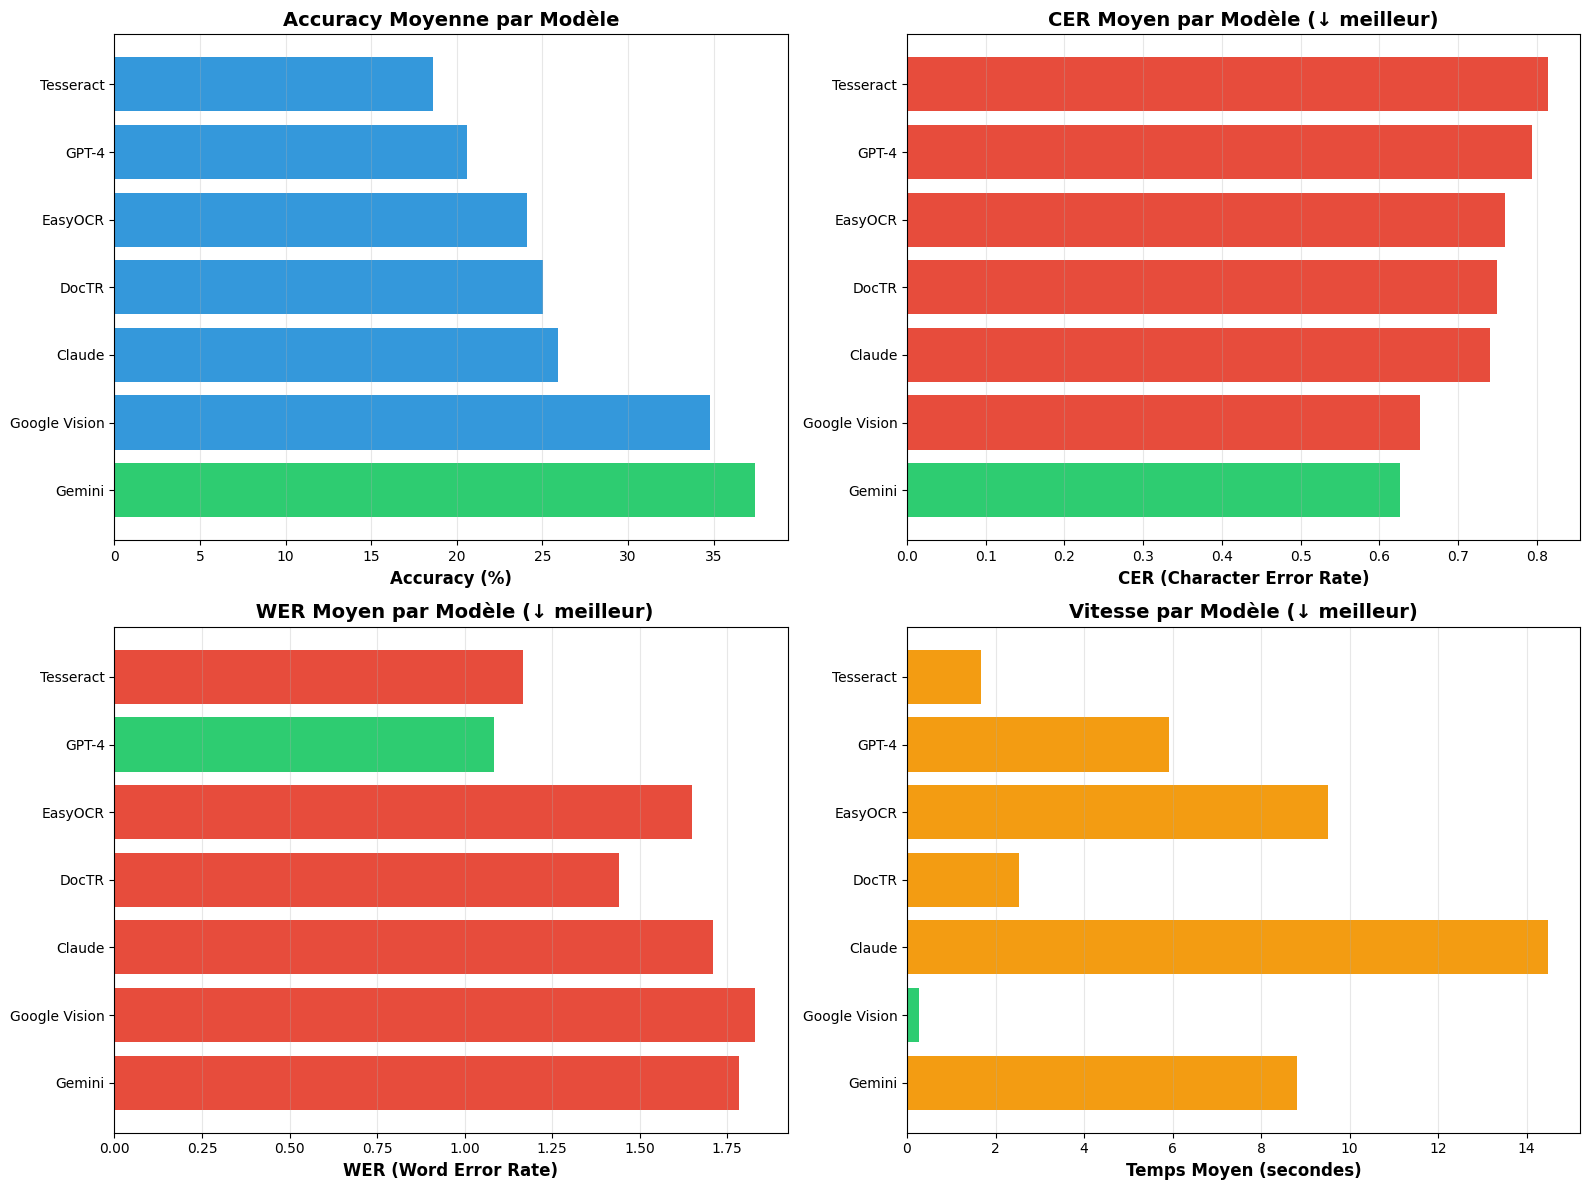

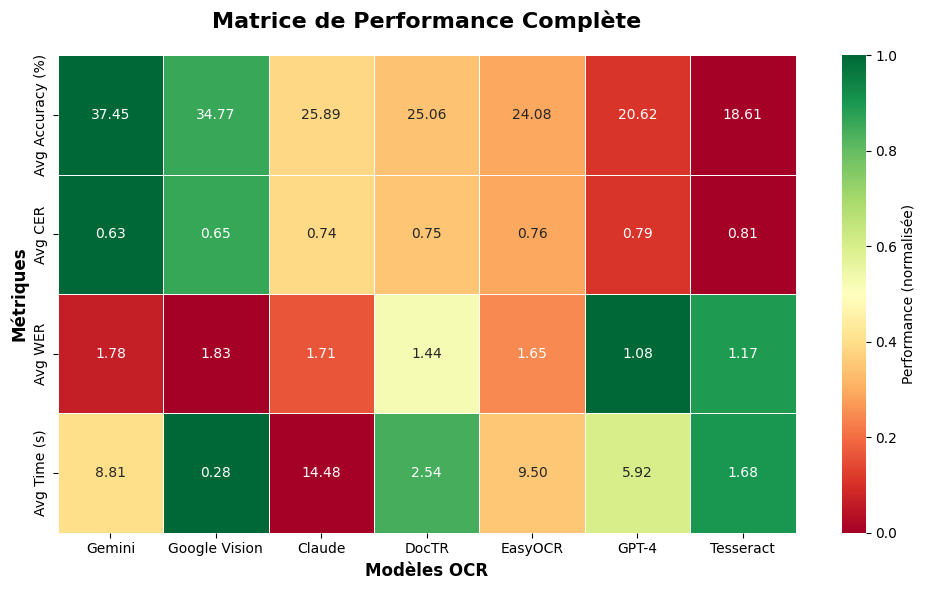

In [30]:
# Visualisation graphique des performances
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Accuracy par modèle
ax1 = axes[0, 0]
colors = ['#2ecc71' if x == summary['Avg Accuracy (%)'].max() else '#3498db' for x in summary['Avg Accuracy (%)']]
ax1.barh(summary['Model'], summary['Avg Accuracy (%)'], color=colors)
ax1.set_xlabel('Accuracy (%)', fontsize=12, fontweight='bold')
ax1.set_title('Accuracy Moyenne par Modèle', fontsize=14, fontweight='bold')
ax1.grid(axis='x', alpha=0.3)

# 2. CER par modèle (plus bas = meilleur)
ax2 = axes[0, 1]
colors = ['#2ecc71' if x == summary['Avg CER'].min() else '#e74c3c' for x in summary['Avg CER']]
ax2.barh(summary['Model'], summary['Avg CER'], color=colors)
ax2.set_xlabel('CER (Character Error Rate)', fontsize=12, fontweight='bold')
ax2.set_title('CER Moyen par Modèle (↓ meilleur)', fontsize=14, fontweight='bold')
ax2.grid(axis='x', alpha=0.3)

# 3. WER par modèle (plus bas = meilleur)
ax3 = axes[1, 0]
colors = ['#2ecc71' if x == summary['Avg WER'].min() else '#e74c3c' for x in summary['Avg WER']]
ax3.barh(summary['Model'], summary['Avg WER'], color=colors)
ax3.set_xlabel('WER (Word Error Rate)', fontsize=12, fontweight='bold')
ax3.set_title(' WER Moyen par Modèle (↓ meilleur)', fontsize=14, fontweight='bold')
ax3.grid(axis='x', alpha=0.3)

# 4. Temps moyen par modèle (plus bas = meilleur)
ax4 = axes[1, 1]
colors = ['#2ecc71' if x == summary['Avg Time (s)'].min() else '#f39c12' for x in summary['Avg Time (s)']]
ax4.barh(summary['Model'], summary['Avg Time (s)'], color=colors)
ax4.set_xlabel('Temps Moyen (secondes)', fontsize=12, fontweight='bold')
ax4.set_title('Vitesse par Modèle (↓ meilleur)', fontsize=14, fontweight='bold')
ax4.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

# Matrice de comparaison (heatmap)
fig, ax = plt.subplots(figsize=(10, 6))
comparison_data = summary[['Model', 'Avg Accuracy (%)', 'Avg CER', 'Avg WER', 'Avg Time (s)']].set_index('Model')

# Normalisation pour la heatmap (0-1)
normalized = comparison_data.copy()
for col in normalized.columns:
    if col in ['Avg CER', 'Avg WER', 'Avg Time (s)']:  # Plus bas = meilleur
        normalized[col] = 1 - (normalized[col] - normalized[col].min()) / (normalized[col].max() - normalized[col].min())
    else:  # Plus haut = meilleur
        normalized[col] = (normalized[col] - normalized[col].min()) / (normalized[col].max() - normalized[col].min())

sns.heatmap(normalized.T, annot=comparison_data.T.values, fmt='.2f', cmap='RdYlGn', 
            cbar_kws={'label': 'Performance (normalisée)'}, linewidths=0.5, ax=ax)
ax.set_title('Matrice de Performance Complète', fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Modèles OCR', fontsize=12, fontweight='bold')
ax.set_ylabel('Métriques', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()